# Bayes' and kNN classifier from scratch: forest vs. urban pixels

**Goal:** classify every pixel of an aerial/satellite image as *forest* or *urban* using two classifiers implemented only with NumPy (no scikit-learn classifiers).

**Plan**
1. Load training images (pure forest, pure urban) and a new test image.
2. Plot histograms of the pixel values and fit parametric PDFs (Gaussians).
3. Bayes classifier: compare posteriors `P(class | pixel)` for every pixel of the new image; colour **red = urban**, **blue = forest**.
4. kNN classifier on the same problem; try k = 1, 3, 5.
5. Compare both methods (accuracy on held-out pixels, confusion matrix, noise in the maps, runtime).

**Files expected next to this notebook:** `forest.png`, `urban.png` (hand-cropped, pixels of one type only) and `test.png` (new image). If they are missing, the notebook generates synthetic images so that it still runs.

In [1]:
import os, time
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

rng = np.random.default_rng(42)
plt.rcParams["figure.dpi"] = 110

# ---------------- configuration ----------------
FOREST_FILE, URBAN_FILE, TEST_FILE = "forest.png", "urban.png", "test.png"
MAX_WIDTH = 300          # test image is shrunk to this width (keeps kNN fast)
TRAIN_FRACTION = 0.7     # left 70% of each training image = training, right 30% = validation
KNN_TRAIN_SAMPLES = 4000 # pixels per class stored by kNN
COLOR_URBAN, COLOR_FOREST = (1, 0, 0), (0, 0, 1)   # red / blue

## 1. Data
Images are converted to RGB floats in [0, 1]. Each **pixel is one sample with 3 features (R, G, B)**.

Images are crops of one Sentinel-2 L2A true-color scene of Kraków (Copernicus Browser, 2026-06-29): forest = Niepołomice Forest, urban = Kraków Old Town, test = western Kraków.

Loaded real images.


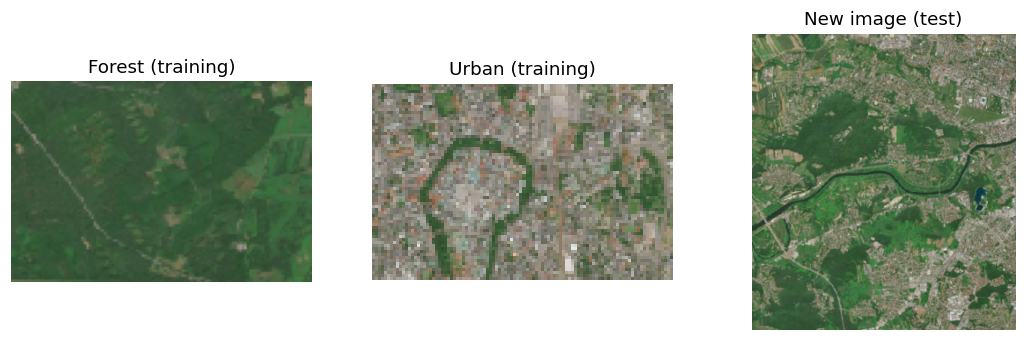

In [2]:
def load_rgb(path, max_width=None):
    img = Image.open(path).convert("RGB")
    if max_width and img.width > max_width:
        img = img.resize((max_width, int(img.height * max_width / img.width)))
    return np.asarray(img, dtype=np.float64) / 255.0

def synthetic_demo():
    """Fallback data so the notebook runs without your images (REPLACE with real images!)."""
    def noise(h, w, s): return rng.normal(0, s, (h, w, 3))
    forest = np.clip(np.array([0.15, 0.32, 0.12]) + noise(120, 160, 0.06), 0, 1)
    urban  = np.clip(np.array([0.50, 0.48, 0.47]) + noise(120, 160, 0.12), 0, 1)
    test = np.clip(np.array([0.15, 0.32, 0.12]) + noise(160, 240, 0.06), 0, 1)
    test[40:120, 80:200] = np.clip(np.array([0.50, 0.48, 0.47]) + noise(80, 120, 0.12), 0, 1)
    return forest, urban, test

if all(os.path.exists(f) for f in (FOREST_FILE, URBAN_FILE, TEST_FILE)):
    forest_img, urban_img, test_img = load_rgb(FOREST_FILE), load_rgb(URBAN_FILE), load_rgb(TEST_FILE, MAX_WIDTH)
    print("Loaded real images.")
else:
    forest_img, urban_img, test_img = synthetic_demo()
    print("!!! Image files not found - using SYNTHETIC demo data !!!")

fig, ax = plt.subplots(1, 3, figsize=(12, 3.5))
for a, im, t in zip(ax, (forest_img, urban_img, test_img), ("Forest (training)", "Urban (training)", "New image (test)")):
    a.imshow(im); a.set_title(t); a.axis("off")
plt.show()

**Train / validation split.** Neighbouring pixels are strongly correlated, so a random pixel split would be too optimistic. I split **spatially**: the left 70 % columns of each training image are used for training, the right 30 % for validation (accuracy and confusion matrix later).

In [3]:
def split_pixels(img, frac):
    w = int(img.shape[1] * frac)
    return img[:, :w].reshape(-1, 3), img[:, w:].reshape(-1, 3)

F_train, F_val = split_pixels(forest_img, TRAIN_FRACTION)
U_train, U_val = split_pixels(urban_img, TRAIN_FRACTION)

# labels: 0 = forest, 1 = urban
X_train = np.vstack([F_train, U_train]); y_train = np.r_[np.zeros(len(F_train)), np.ones(len(U_train))]
X_val   = np.vstack([F_val, U_val]);     y_val   = np.r_[np.zeros(len(F_val)),   np.ones(len(U_val))]
print(f"train: {len(F_train)} forest + {len(U_train)} urban pixels | validation: {len(F_val)} + {len(U_val)}")

train: 6720 forest + 4550 urban pixels | validation: 2880 + 1950


## 2. Histograms and parametric PDF models

For each class and each colour channel I plot the normalised histogram and fit a **Gaussian** by maximum likelihood:

$$\hat\mu=\frac1N\sum_i x_i,\qquad \hat\sigma^2=\frac1N\sum_i (x_i-\hat\mu)^2 ,\qquad p(x)=\frac{1}{\sqrt{2\pi\sigma^2}}\exp\!\Big(-\frac{(x-\mu)^2}{2\sigma^2}\Big)$$

The visual match between histogram and curve tells us whether a Gaussian is a reasonable model.

class    chan       mu   sigma
forest   R       0.237   0.046
forest   G       0.350   0.031
forest   B       0.234   0.029
urban    R       0.508   0.119
urban    G       0.507   0.087
urban    B       0.441   0.115


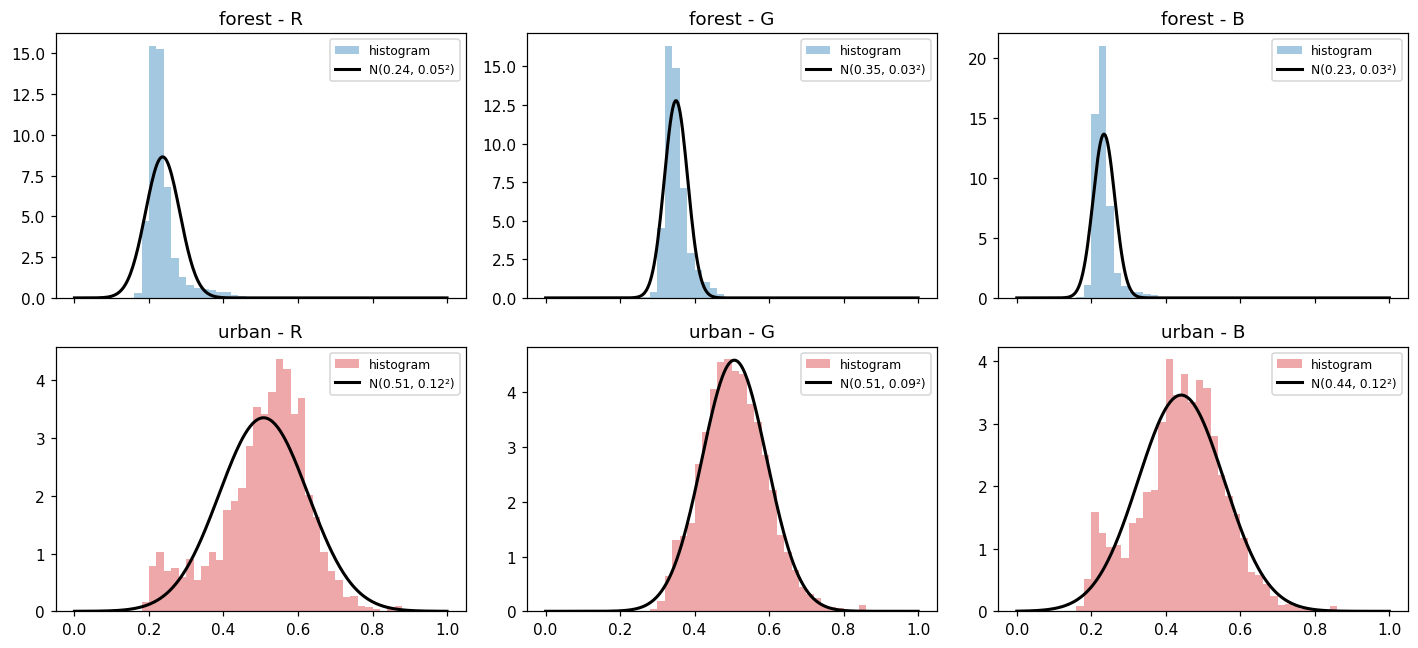

In [4]:
def gauss_pdf_1d(x, mu, sigma):
    return np.exp(-0.5 * ((x - mu) / sigma) ** 2) / (np.sqrt(2 * np.pi) * sigma)

channels = ["R", "G", "B"]
x = np.linspace(0, 1, 300)
fig, ax = plt.subplots(2, 3, figsize=(13, 6), sharex=True)
print(f"{'class':8s} {'chan':5s} {'mu':>7s} {'sigma':>7s}")
for row, (name, data, col) in enumerate([("forest", F_train, "tab:blue"), ("urban", U_train, "tab:red")]):
    for c in range(3):
        mu, sigma = data[:, c].mean(), data[:, c].std()
        ax[row, c].hist(data[:, c], bins=50, range=(0, 1), density=True, color=col, alpha=0.4, label="histogram")
        ax[row, c].plot(x, gauss_pdf_1d(x, mu, sigma), "k", lw=2, label=f"N({mu:.2f}, {sigma:.2f}²)")
        ax[row, c].set_title(f"{name} - {channels[c]}"); ax[row, c].legend(fontsize=8)
        print(f"{name:8s} {channels[c]:5s} {mu:7.3f} {sigma:7.3f}")
plt.tight_layout(); plt.show()

**Joint model.** The channels are strongly correlated (a bright pixel is bright in R, G and B), so treating them as independent would be wrong. I therefore model each class with a **multivariate Gaussian** (mean vector $\mu_k$ and covariance matrix $\Sigma_k$, estimated by maximum likelihood). The 1-D fits above are its marginals.

In [5]:
def fit_gaussian(X, eps=1e-6):
    mu = X.mean(axis=0)
    cov = np.cov(X, rowvar=False) + eps * np.eye(X.shape[1])   # eps keeps cov invertible
    return mu, cov

def log_gauss(X, mu, cov):
    """log N(x | mu, cov) for each row of X."""
    d = X - mu
    maha = np.einsum("ij,jk,ik->i", d, np.linalg.inv(cov), d)   # Mahalanobis distance^2
    _, logdet = np.linalg.slogdet(cov)
    return -0.5 * (maha + logdet + X.shape[1] * np.log(2 * np.pi))

mu_f, cov_f = fit_gaussian(F_train)
mu_u, cov_u = fit_gaussian(U_train)
print("forest mu:", mu_f.round(3)); print("urban  mu:", mu_u.round(3))
print("forest cov:\n", cov_f.round(4)); print("urban cov:\n", cov_u.round(4))

forest mu: [0.237 0.35  0.234]
urban  mu: [0.508 0.507 0.441]
forest cov:
 [[0.0021 0.0011 0.0012]
 [0.0011 0.001  0.0007]
 [0.0012 0.0007 0.0009]]
urban cov:
 [[0.0142 0.0093 0.0126]
 [0.0093 0.0076 0.0097]
 [0.0126 0.0097 0.0133]]


## 3. Bayes classifier

Bayes decision rule (minimum error): choose the class with the larger posterior

$$P(\text{urban}\mid x)\;\gtrless\; P(\text{forest}\mid x)\iff \underbrace{\frac{p(x\mid \text{urban})}{p(x\mid \text{forest})}}_{\text{likelihood ratio}}\;\gtrless\;\frac{P(\text{forest})}{P(\text{urban})}$$

Priors are estimated from the class sizes in the training set (equal here, since both classes are cropped to the same size - they can be changed to encode prior knowledge about the scene). Everything is computed in **log space** to avoid numerical underflow.

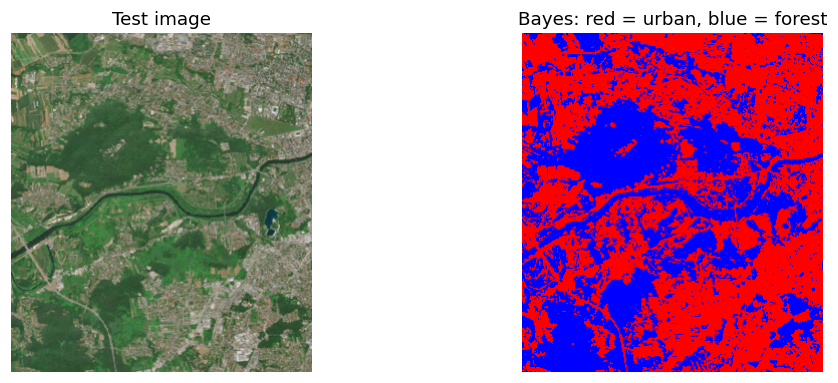

urban fraction: 57.6%


In [6]:
prior_f = len(F_train) / len(X_train)
prior_u = len(U_train) / len(X_train)

def bayes_predict(X, prior_f=prior_f, prior_u=prior_u):
    """Return 1 (urban) / 0 (forest) for every row of X."""
    log_post_f = log_gauss(X, mu_f, cov_f) + np.log(prior_f)   # log p(x|f) + log P(f)
    log_post_u = log_gauss(X, mu_u, cov_u) + np.log(prior_u)
    return (log_post_u > log_post_f).astype(int)

def colorize(labels, shape):
    out = np.zeros((*shape[:2], 3))
    lab = labels.reshape(shape[:2])
    out[lab == 1] = COLOR_URBAN; out[lab == 0] = COLOR_FOREST
    return out

H, W, _ = test_img.shape
bayes_map = bayes_predict(test_img.reshape(-1, 3))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].imshow(test_img); ax[0].set_title("Test image"); ax[1].imshow(colorize(bayes_map, test_img.shape))
ax[1].set_title("Bayes: red = urban, blue = forest")
for a in ax: a.axis("off")
plt.show()
print(f"urban fraction: {bayes_map.mean():.1%}")

In [7]:
def confusion(y_true, y_pred):
    cm = np.zeros((2, 2), int)
    for t, p in zip(y_true.astype(int), y_pred.astype(int)): cm[t, p] += 1
    return cm

def report(name, y_true, y_pred):
    cm = confusion(y_true, y_pred)
    print(f"{name}: accuracy = {np.mean(y_true == y_pred):.3f}")
    print("            pred forest  pred urban")
    print(f"true forest {cm[0,0]:11d} {cm[0,1]:11d}\ntrue urban  {cm[1,0]:11d} {cm[1,1]:11d}\n")

report("Bayes (validation pixels)", y_val, bayes_predict(X_val))

Bayes (validation pixels): accuracy = 0.896
            pred forest  pred urban
true forest        2607         273
true urban          227        1723



**Discussion (Bayes).** The classifier is parametric: after training it only stores 2 means, 2 covariance matrices and 2 priors, so prediction is extremely fast. Its quality depends on how well the Gaussian assumption fits the data. Where the histograms above are skewed or multimodal (e.g. an urban area mixing roofs, roads and concrete) a single Gaussian is a poor fit, which produces errors. The result is also a *per-pixel* decision with no spatial context, so isolated misclassified pixels ("salt and pepper") appear.

## 4. kNN classifier from scratch

Non-parametric: no model is fitted. A new pixel gets the **majority label of its k nearest training pixels** (Euclidean distance in RGB space). Steps:
1. Store training samples (a random subsample per class keeps the cost manageable: cost is O(N_test · N_train)).
2. For every test pixel compute distances to all stored samples (vectorised, in chunks to limit memory).
3. Pick the k smallest distances, vote, assign the label.

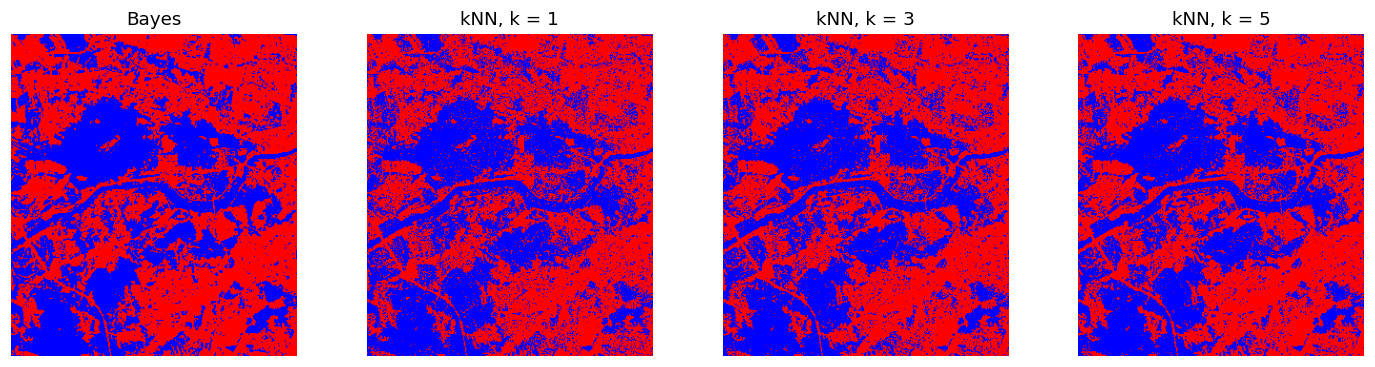

In [8]:
def balanced_subsample(A, B, n):
    ia = rng.choice(len(A), min(n, len(A)), replace=False)
    ib = rng.choice(len(B), min(n, len(B)), replace=False)
    X = np.vstack([A[ia], B[ib]]); y = np.r_[np.zeros(len(ia)), np.ones(len(ib))]
    return X, y

Xk, yk = balanced_subsample(F_train, U_train, KNN_TRAIN_SAMPLES)

def knn_predict(X_test, X_tr, y_tr, k, chunk=5000):
    preds = np.empty(len(X_test), dtype=int)
    tr_sq = (X_tr ** 2).sum(1)
    for s in range(0, len(X_test), chunk):
        Q = X_test[s:s + chunk]
        # squared Euclidean distance: |q|^2 + |t|^2 - 2 q.t
        D = (Q ** 2).sum(1)[:, None] + tr_sq[None, :] - 2 * Q @ X_tr.T
        idx = np.argpartition(D, k - 1, axis=1)[:, :k]      # indices of k nearest
        votes = y_tr[idx].mean(axis=1)                       # fraction of 'urban' neighbours
        preds[s:s + chunk] = (votes > 0.5).astype(int)       # use odd k -> no ties
    return preds

Xt = test_img.reshape(-1, 3)
knn_maps, knn_times = {}, {}
for k in (1, 3, 5):
    t0 = time.time(); knn_maps[k] = knn_predict(Xt, Xk, yk, k); knn_times[k] = time.time() - t0

fig, ax = plt.subplots(1, 4, figsize=(16, 3.8))
ax[0].imshow(colorize(bayes_map, test_img.shape)); ax[0].set_title("Bayes")
for a, k in zip(ax[1:], (1, 3, 5)):
    a.imshow(colorize(knn_maps[k], test_img.shape)); a.set_title(f"kNN, k = {k}")
for a in ax: a.axis("off")
plt.show()

In [9]:
print("Validation accuracy (held-out right-hand part of the training images)")
for k in (1, 3, 5):
    report(f"kNN k={k}", y_val, knn_predict(X_val, Xk, yk, k))

# agreement with Bayes on the test image and map 'noisiness' (fraction of pixels whose right neighbour has a different label)
def noisiness(lab): m = lab.reshape(H, W); return np.mean(m[:, 1:] != m[:, :-1])
print(f"{'method':10s} {'urban %':>8s} {'agree w/ Bayes':>15s} {'label flips':>12s} {'time [s]':>9s}")
print(f"{'Bayes':10s} {bayes_map.mean():8.1%} {'-':>15s} {noisiness(bayes_map):12.3f} {'-':>9s}")
for k in (1, 3, 5):
    print(f"{'kNN k='+str(k):10s} {knn_maps[k].mean():8.1%} {np.mean(knn_maps[k]==bayes_map):15.1%} {noisiness(knn_maps[k]):12.3f} {knn_times[k]:9.2f}")

Validation accuracy (held-out right-hand part of the training images)
kNN k=1: accuracy = 0.877
            pred forest  pred urban
true forest        2543         337
true urban          258        1692

kNN k=3: accuracy = 0.892
            pred forest  pred urban
true forest        2590         290
true urban          234        1716

kNN k=5: accuracy = 0.892
            pred forest  pred urban
true forest        2569         311
true urban          211        1739

method      urban %  agree w/ Bayes  label flips  time [s]
Bayes         57.6%               -        0.140         -
kNN k=1       55.4%           83.9%        0.219     16.86
kNN k=3       56.4%           86.8%        0.187     15.91
kNN k=5       57.5%           88.0%        0.172     18.47


## 5. Extra analysis

**(a) Effect of k.** Accuracy on the validation pixels for a wider range of odd k.
**(b) Effect of the Bayes prior.** Changing the prior shifts the decision boundary.

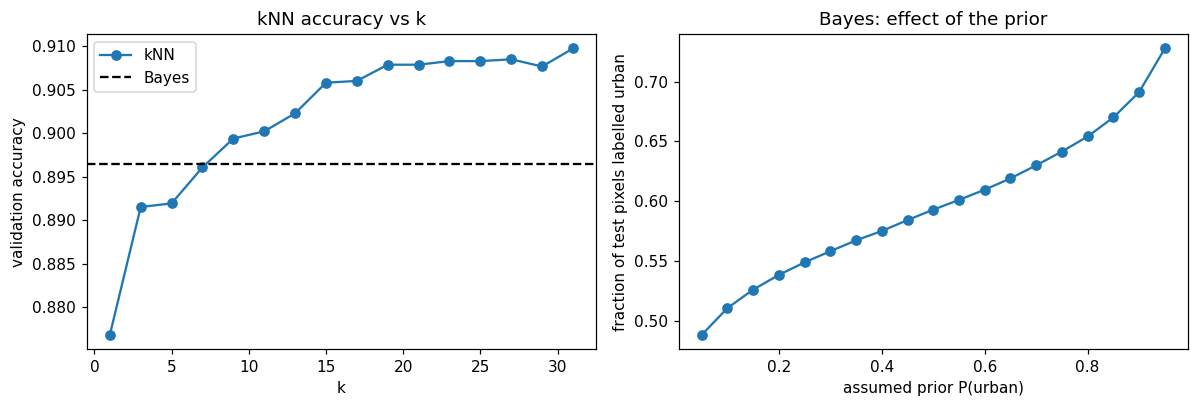

In [10]:
ks = list(range(1, 32, 2))
accs = [np.mean(knn_predict(X_val, Xk, yk, k) == y_val) for k in ks]
bayes_acc = np.mean(bayes_predict(X_val) == y_val)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(ks, accs, "o-", label="kNN"); ax[0].axhline(bayes_acc, color="k", ls="--", label="Bayes")
ax[0].set_xlabel("k"); ax[0].set_ylabel("validation accuracy"); ax[0].legend(); ax[0].set_title("kNN accuracy vs k")

pu = np.linspace(0.05, 0.95, 19)
ax[1].plot(pu, [bayes_predict(Xt, 1 - p, p).mean() for p in pu], "o-")
ax[1].set_xlabel("assumed prior P(urban)"); ax[1].set_ylabel("fraction of test pixels labelled urban")
ax[1].set_title("Bayes: effect of the prior")
plt.tight_layout(); plt.show()

## 6. Conclusions

### Bayes classifier
Each class was modelled with a multivariate Gaussian in RGB space. The forest class is compact (σ ≈ 0.03–0.05 per channel), while the urban class is much more spread out (σ ≈ 0.09–0.12), because it mixes roofs, roads, concrete and vegetation. A single Gaussian therefore describes forest well and urban only roughly. On the held-out validation pixels the Bayes classifier reached **89.6 %** accuracy. Its map is the smoothest of all methods (label-flip rate 0.140) and prediction is very fast, because only 2 means, 2 covariance matrices and 2 priors are stored.

The prior shifts the decision boundary: increasing the assumed P(urban) from 0.05 to 0.95 raises the fraction of test pixels labelled urban from about 49 % to 73 %. This matters mostly for ambiguous pixels (e.g. bright green fields).

### kNN classifier: effect of k
| k | validation accuracy | label-flip rate (noise) |
|---|---|---|
| 1 | 87.7 % | 0.219 |
| 3 | 89.2 % | 0.187 |
| 5 | 89.2 % | 0.172 |

- **k = 1** copies every single training pixel, including atypical ones, so it has low bias but high variance. The map is the most noisy ("salt and pepper") and its accuracy is the lowest.
- **k = 3** gives the largest improvement: isolated wrong votes are outvoted by neighbours, and accuracy rises by about 1.5 percentage points.
- **k = 5** smooths the map further (fewer label flips) with the same accuracy as k = 3.
- In the extended sweep, accuracy keeps increasing up to about 91 % for k ≈ 15–31, then flattens. From k ≈ 7 kNN is slightly better than Bayes on validation pixels. Very large k would eventually over-smooth the decision boundary.

### Bayes vs kNN
- Bayes is parametric: fast, compact, smooth, and its behaviour can be controlled through priors, but it fails when the Gaussian assumption is wrong (the multi-modal urban class).
- kNN makes no distributional assumption and can follow arbitrary class shapes, but it must store the training data and is slow (about 16–18 s for one test image here, versus a fraction of a second for Bayes). For small k it is noisier than Bayes.

### Errors and limitations
Both methods classify each pixel by its colour only, with no spatial context or texture. On the test image this causes systematic mistakes:
- Bright green meadows and fields are often labelled **urban**, because they are lighter than the dense forest used for training (Puszcza Niepołomicka); the test image contains a different forest (Las Wolski) with slightly different colours.
- The dark river and its shadows are labelled **forest**, because dark green-grey water has colours similar to dense canopy.
- Park areas inside the city (e.g. the Planty ring included in the urban training crop) blur the urban class.

### Possible improvements
Add texture features (e.g. local standard deviation in a 3×3 window), use the near-infrared band of Sentinel-2 (NDVI separates vegetation from buildings), use a Gaussian mixture instead of one Gaussian per class, or post-process the label map with a majority filter to remove isolated pixels.